# Model Building

In this stage, the cleaned dataset will be prepared and used to build an **Artificial Neural Network (ANN)** for predicting online shopper purchase intention.

The data will first be divided into input features and the target variable, followed by **categorical encoding, feature scaling, and train-test splitting**. The ANN will then be built, trained, and evaluated using appropriate classification metrics.

Since `Revenue` is a binary target, the model will predict whether a shopping session results in:

- **0 → No Purchase**
- **1 → Purchase**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv(r'Data/online_shoppers_intention_cleaned.csv')
data

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  object 
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType           

## Separate Features and Target

In [4]:
X = data.drop('Revenue', axis=1)
y = data['Revenue']

In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12205, 17)
y shape: (12205,)


## Define Feature Types

In [6]:
numerical_cols = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

In [7]:
categorical_cols = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType'
]

In [8]:
boolean_cols = ['Weekend']

## Train-Test Split

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
X_train

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
7469,8,203.6,1,0.0,42,1052.400000,0.000000,0.004545,37.357258,0.0,Nov,2,2,5,2,Returning_Visitor,False
11804,0,0.0,0,0.0,30,901.288889,0.000000,0.007333,34.148420,0.0,Dec,2,2,7,2,New_Visitor,False
3250,0,0.0,0,0.0,13,421.166667,0.000000,0.028205,0.000000,0.8,May,1,1,1,2,Returning_Visitor,False
204,2,40.0,0,0.0,5,558.500000,0.000000,0.028571,0.000000,0.0,Mar,2,2,7,2,New_Visitor,True
4392,0,0.0,0,0.0,16,1599.266667,0.000000,0.013333,0.000000,0.0,May,4,2,2,13,Returning_Visitor,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7864,0,0.0,0,0.0,5,883.600000,0.000000,0.000000,125.893909,0.0,Nov,2,2,4,2,Returning_Visitor,True
7180,4,265.0,0,0.0,22,616.203333,0.003846,0.010470,0.000000,0.0,Nov,3,2,6,2,Returning_Visitor,True
9087,0,0.0,0,0.0,5,51.000000,0.000000,0.040000,0.000000,0.0,Nov,3,2,3,13,Returning_Visitor,False
3645,0,0.0,0,0.0,7,262.375000,0.009524,0.026984,0.000000,0.0,May,1,1,1,6,Returning_Visitor,False


In [12]:
X_test

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
11640,0,0.000000,0,0.0,12,482.500000,0.020000,0.040000,0.000000,0.0,Nov,1,2,1,10,Returning_Visitor,False
6936,2,287.200000,0,0.0,16,473.283333,0.000000,0.002222,0.000000,0.0,Oct,2,2,1,2,New_Visitor,True
7194,2,187.900000,4,100.1,29,2107.033333,0.000000,0.024242,0.000000,0.0,Oct,1,1,3,1,Returning_Visitor,False
11263,7,280.266667,0,0.0,11,329.683333,0.000000,0.023077,0.000000,0.0,Dec,2,2,7,2,Returning_Visitor,False
4728,0,0.000000,0,0.0,5,0.000000,0.200000,0.200000,0.000000,0.0,May,3,2,5,6,Returning_Visitor,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2442,0,0.000000,0,0.0,23,1516.966667,0.000000,0.024242,0.000000,0.2,May,1,1,8,1,Returning_Visitor,False
6927,5,20.000000,0,0.0,72,3220.887143,0.024937,0.061689,0.975803,0.0,Oct,4,1,2,1,Returning_Visitor,False
2874,0,0.000000,1,44.0,14,549.500000,0.000000,0.013333,43.252000,0.2,May,2,4,1,2,New_Visitor,False
12174,3,9.000000,0,0.0,17,372.250000,0.000000,0.016667,0.000000,0.0,Nov,4,1,3,1,Returning_Visitor,False


In [13]:
y_train

7469      True
11804     True
3250     False
204      False
4392     False
         ...  
7864      True
7180     False
9087     False
3645     False
7935     False
Name: Revenue, Length: 9764, dtype: bool

In [14]:
y_test

11640    False
6936     False
7194     False
11263    False
4728     False
         ...  
2442     False
6927     False
2874      True
12174    False
10314    False
Name: Revenue, Length: 2441, dtype: bool

In [15]:
print("Training:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting:")
print(y_test.value_counts(normalize=True) * 100)

Training:
Revenue
False    84.371159
True     15.628841
Name: proportion, dtype: float64

Testing:
Revenue
False    84.350676
True     15.649324
Name: proportion, dtype: float64


In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)

In [17]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (7811, 17) (7811,)
Validation: (1953, 17) (1953,)
Testing: (2441, 17) (2441,)


## Data Preprocessing

In [18]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [19]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train['Weekend'] = X_train['Weekend'].astype(int)
X_test['Weekend'] = X_test['Weekend'].astype(int)

In [20]:
X_train['Weekend'].value_counts()

Weekend
0    6007
1    1804
Name: count, dtype: int64

In [21]:
X_test['Weekend'].value_counts()

Weekend
0    1866
1     575
Name: count, dtype: int64

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'
)

- Here `remainder='passthrough'` keeps columns that aren't included in numerical_cols or categorical_cols. In this case that's `Weekend`. It is not included in either numerical_cols or categorical_cols, and have already converted to 0/1.

In [23]:
X_train_processed = preprocessor.fit_transform(X_train)

In [24]:
X_val_processed = preprocessor.transform(X_val)

In [25]:
X_test_processed = preprocessor.transform(X_test)

In [26]:
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (7811, 73)
Validation: (1953, 73)
Testing: (2441, 73)


In [27]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

In [28]:
print(y_train.value_counts())

Revenue
0    6590
1    1221
Name: count, dtype: int64


In [29]:
print(y_test.value_counts())

Revenue
0    2059
1     382
Name: count, dtype: int64


# 1. BUILD BASELINE ANN MODEL

## Build the Baseline ANN

In [30]:
import tensorflow as tf
from tensorflow.keras import layers,models

In [31]:
model = models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train_processed.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')])

## Compile the ANN Model

In [32]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

#### What this means
- optimizer='adam' → Adjusts the ANN's weights during training to reduce errors.
- loss='binary_crossentropy' → Measures the model's error. It is suitable because `Revenue` is a binary target (`0` or `1`).
- metrics=['accuracy'] → Tracks accuracy during training.

In [33]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │           1,184 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,329 (5.19 KB)

 Trainable params: 1,329 (5.19 KB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [34]:
history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7833 - loss: 0.4673 - val_accuracy: 0.8597 - val_loss: 0.3393
Epoch 2/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8814 - loss: 0.2910 - val_accuracy: 0.8833 - val_loss: 0.2898
Epoch 3/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8912 - loss: 0.2629 - val_accuracy: 0.8822 - val_loss: 0.2817
Epoch 4/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8958 - loss: 0.2521 - val_accuracy: 0.8822 - val_loss: 0.2756
Epoch 5/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8983 - loss: 0.2452 - val_accuracy: 0.8822 - val_loss: 0.2702
Epoch 6/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9018 - loss: 0.2399 - val_accuracy: 0.8817 - val_loss: 0.2685
Epoch 7/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9017 - loss: 0.2359 - val_accuracy: 0.8838 - val_loss: 0.2651
Epoch 8/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9041 - loss: 0.2328 - val_accuracy: 0.

## Check Loss and Accuracy

In [35]:
val_loss, val_accuracy = model.evaluate(X_val_processed, y_val)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8812 - loss: 0.2892
Validation Loss: 0.28922900557518005
Validation Accuracy: 0.8812084197998047


## Training and Validation Graphs

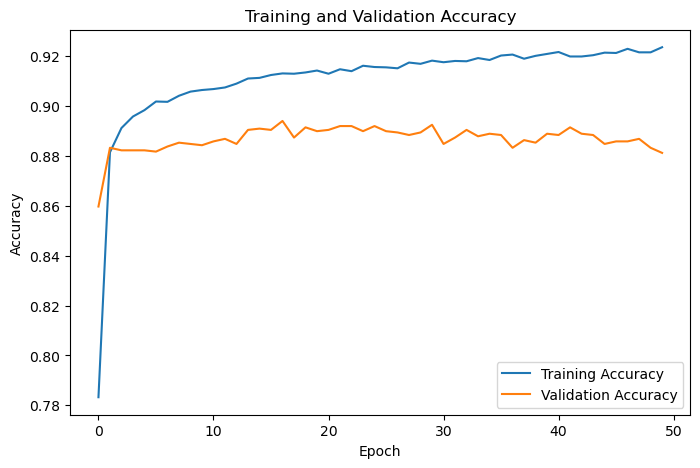

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

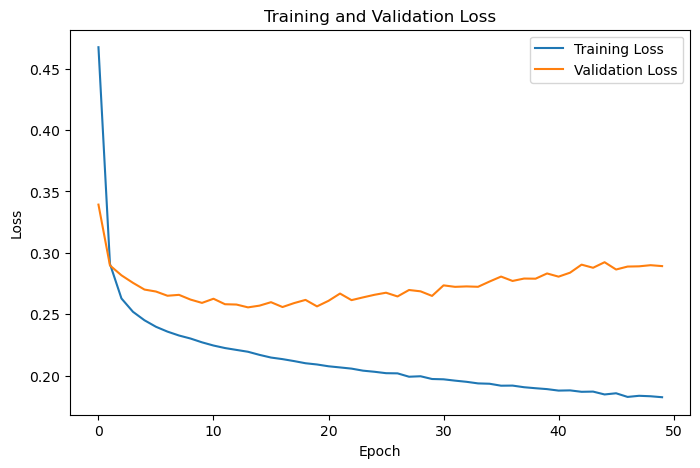

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

## Baseline ANN – Training and Validation Analysis

### 1. Training and Validation Accuracy

- The **training accuracy** increased from approximately **78% to 92%**.
- The **validation accuracy** initially improved and reached approximately **89.5–89.7% around epochs 12–15**.
- After this point, validation accuracy fluctuated and slightly decreased.
- The final validation accuracy was approximately **88.53%**.

**Interpretation:**  
Additional training improves the model's performance on the training data but does not improve its performance on unseen validation data. This further indicates **overfitting**.

### 2. Training and Validation Loss

- The **training loss** continuously decreased from approximately **0.46 to 0.19**.
- The **validation loss** initially decreased from approximately **0.32 to 0.25**.
- The validation loss reached its minimum around **epochs 12–15**.
- After this point, the validation loss gradually increased while the training loss continued to decrease.

**Interpretation:**  
The model begins to **overfit after approximately 12–15 epochs**. It continues learning patterns specific to the training data, but its ability to generalize to unseen validation data starts to decrease.

### 3. Overall Conclusion

| Metric | Observation |
|---|---|
| Training Loss | Continuously decreases |
| Validation Loss | Decreases initially, then increases |
| Training Accuracy | Reaches approximately 92% |
| Validation Accuracy | Peaks around 89.5–89.7% |
| Overfitting | Yes, after approximately 12–15 epochs |
| Best Performance Region | Around epochs 12–15 |

The baseline ANN shows good learning performance, but training for all **50 epochs is unnecessary** because validation performance begins to deteriorate after approximately 12–15 epochs.

### 4. Model Improvement

The most appropriate first improvement is to use **Early Stopping**.

Early Stopping monitors the validation loss during training and automatically stops training when the validation loss stops improving. Using `restore_best_weights=True` also restores the model weights from the epoch with the best validation performance.

The same **16 → 8 → 1 ANN architecture** can be retained initially because the network is already relatively simple. Further techniques such as **Dropout** or **L2 regularization** can be considered later if overfitting remains a problem.

After controlling overfitting, the model should also be evaluated using **Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix**, since the target variable is imbalanced.

# 2. BUILD ANN MODEL USING EARLY STOPPING

## Improve the ANN Using Early Stopping

In [38]:
model_es = models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train_processed.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

## Compile the Model

In [39]:
model_es.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Early Stopping

In [40]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

#### Here:
- `monitor='val_loss'` → monitors validation loss.
- `patience=5` → waits for 5 epochs without improvement before stopping.
- `restore_best_weights=True` → after stopping, restores the weights from the epoch with the lowest validation loss.

So if the best validation loss occurs at epoch 14 but training stops at epoch 19, the final model will use the weights from approximately epoch 14, not epoch 19.

## Train the Model

In [41]:
history_es = model_es.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8232 - loss: 0.3972 - val_accuracy: 0.8612 - val_loss: 0.3215
Epoch 2/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8829 - loss: 0.2861 - val_accuracy: 0.8781 - val_loss: 0.2868
Epoch 3/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8919 - loss: 0.2604 - val_accuracy: 0.8827 - val_loss: 0.2824
Epoch 4/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8960 - loss: 0.2511 - val_accuracy: 0.8853 - val_loss: 0.2786
Epoch 5/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8992 - loss: 0.2451 - val_accuracy: 0.8838 - val_loss: 0.2737
Epoch 6/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8992 - loss: 0.2415 - val_accuracy: 0.8843 - val_loss: 0.2717
Epoch 7/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9001 - loss: 0.2368 - val_accuracy: 0.8817 - val_loss: 0.2702
Epoch 8/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9015 - loss: 0.2338 - val_accuracy: 0.

## Check Loss and Accuracy

In [42]:
val_loss_es, val_accuracy_es = model_es.evaluate(
    X_val_processed,
    y_val
)

print("Validation Loss:", val_loss_es)
print("Validation Accuracy:", val_accuracy_es)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8858 - loss: 0.2604
Validation Loss: 0.2604477107524872
Validation Accuracy: 0.8858166933059692


## Evaluate the ANN with Classification Metrics

In [43]:
y_val_prob = model_es.predict(X_val_processed).ravel()

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [44]:
y_val_pred = (y_val_prob >= 0.5).astype(int)

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall   :", recall_score(y_val, y_val_pred))
print("F1 Score :", f1_score(y_val, y_val_pred))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob))

Accuracy : 0.8858166922683052
Precision: 0.6496350364963503
Recall   : 0.5836065573770491
F1 Score : 0.614853195164076
ROC-AUC  : 0.9084772401718926


## Classification Report

In [46]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

       False       0.92      0.94      0.93      1648
        True       0.65      0.58      0.61       305

    accuracy                           0.89      1953
   macro avg       0.79      0.76      0.77      1953
weighted avg       0.88      0.89      0.88      1953



## Confusion Matrix

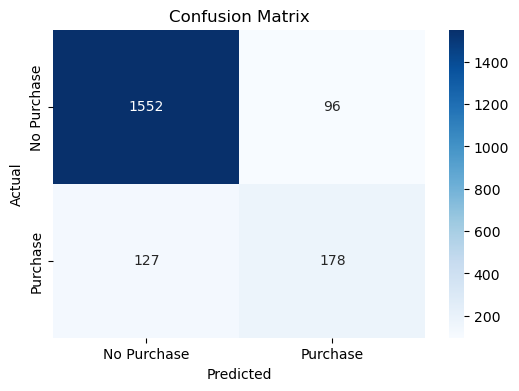

In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Purchase', 'Purchase'],
    yticklabels=['No Purchase', 'Purchase']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

## Roc Auc Score

In [48]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_val, y_val_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9084772401718926


## Early-Stopping ANN – Model Evaluation

The ANN model was retrained using **Early Stopping** to reduce the overfitting observed in the baseline model. The same **16 → 8 → 1 architecture** was retained for a fair comparison.

### 1. Validation Performance

The Early-Stopping ANN produced the following validation results:

| Metric | Score |
|---|---:|
| Validation Loss | 0.2604 |
| Validation Accuracy | 88.58% |

Early Stopping helped control the overfitting observed in the baseline ANN by monitoring the validation loss and restoring the weights from the best-performing epoch.

### 2. Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| No Purchase | 0.92 | 0.94 | 0.93 | 1648 |
| Purchase | 0.65 | 0.58 | 0.61 | 305 |
| **Accuracy** |  |  | **0.89** | **1953** |
| Macro Average | 0.79 | 0.76 | 0.77 | 1953 |
| Weighted Average | 0.88 | 0.89 | 0.88 | 1953 |

The model performs well in identifying **No Purchase** sessions. However, its performance for the minority **Purchase** class is comparatively weaker.

For the Purchase class:

- **Precision = 0.65:** About 65% of the sessions predicted as purchases were actual purchases.
- **Recall = 0.58:** The model identified about 58% of all actual purchasers.
- **F1-score = 0.61:** The balance between precision and recall for the Purchase class is moderate.

### 3. Confusion Matrix

| Actual / Predicted | No Purchase | Purchase |
|---|---:|---:|
| **No Purchase** | 1552 | 96 |
| **Purchase** | 127 | 178 |

The confusion matrix shows:

- **True Negatives (TN) = 1552:** No Purchase sessions correctly identified.
- **False Positives (FP) = 96:** No Purchase sessions incorrectly predicted as Purchase.
- **False Negatives (FN) = 127:** Actual Purchase sessions incorrectly predicted as No Purchase.
- **True Positives (TP) = 178:** Purchase sessions correctly identified.

Out of **305 actual purchasers**, the model correctly identified **178** and missed **127**.

Therefore, the model detects approximately **58% of actual purchasers** at the default classification threshold of 0.5.

### 4. ROC-AUC Score

The model achieved:

**ROC-AUC = 0.9085**

The ROC-AUC score measures the model's ability to distinguish between the two classes across different classification thresholds.

A score of approximately **0.91** indicates that the Early-Stopping ANN has a strong ability to distinguish between Purchase and No Purchase sessions based on its predicted probabilities.

### 5. Overall Conclusion

The Early-Stopping ANN achieved a **validation loss of 0.2604**, **validation accuracy of approximately 88.58%**, and a strong **ROC-AUC score of 0.9085**.

The model performs particularly well for the majority **No Purchase** class. However, at the default classification threshold of 0.5, the Purchase class has a recall of only approximately **58%**.

This means that although the model has strong overall discrimination, it still misses **127 out of 305 actual purchasers**.

Therefore, Early Stopping helps control overfitting, but the **class imbalance remains an important issue**. The next step is to evaluate the same ANN using **class weights** and compare its Precision, Recall, F1-score, ROC-AUC, and confusion matrix with the Early-Stopping model.

# 3. BUILD ANN USING CLASS WEIGHTS

## Handle Class Imbalance Using Class Weights

In [49]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(0.5926403641881639), np.int64(1): np.float64(3.198607698607699)}


- `np.unique(y_train)` → Finds the target classes 0 and 1.
- `compute_class_weight()` → Calculates a suitable weight for each class.
- `class_weight='balanced'` → Gives a higher weight to the minority class and a lower weight to the majority class.
- `y=y_train` → Calculates the weights using only the training data.
- `dict(zip(classes, weights))` → Converts the calculated weights into a dictionary that can be passed to the ANN.

## Building the Model

In [50]:
model_cw = models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train_processed.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

## Compile the Model

In [51]:
model_cw.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Early Stopping

In [52]:
early_stopping_cw = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

## Train the Model

In [53]:
history_cw = model_cw.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping_cw],
    verbose=1
)

Epoch 1/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5127 - loss: 0.6030 - val_accuracy: 0.7911 - val_loss: 0.5196
Epoch 2/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8173 - loss: 0.4283 - val_accuracy: 0.8259 - val_loss: 0.4473
Epoch 3/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8332 - loss: 0.3958 - val_accuracy: 0.8331 - val_loss: 0.4365
Epoch 4/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8507 - loss: 0.3806 - val_accuracy: 0.8090 - val_loss: 0.4814
Epoch 5/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8516 - loss: 0.3682 - val_accuracy: 0.8484 - val_loss: 0.3870
Epoch 6/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8544 - loss: 0.3611 - val_accuracy: 0.8315 - val_loss: 0.4167
Epoch 7/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8542 - loss: 0.3539 - val_accuracy: 0.8331 - val_loss: 0.4059
Epoch 8/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8511 - loss: 0.3473 - val_accuracy: 0.

In [54]:
print("Epochs run:", len(history_cw.history['loss']))

Epochs run: 10


## Check Loss and Accuracy

In [55]:
val_loss_cw, val_accuracy_cw = model_cw.evaluate(
    X_val_processed,
    y_val
)

print("Validation Loss:", val_loss_cw)
print("Validation Accuracy:", val_accuracy_cw)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8484 - loss: 0.3870
Validation Loss: 0.38700544834136963
Validation Accuracy: 0.8484383225440979


In [56]:
y_val_prob_cw = model_cw.predict(X_val_processed).ravel()

y_val_pred_cw = (y_val_prob_cw >= 0.5).astype(int)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


## Classification Report

In [57]:
print(classification_report(y_val, y_val_pred_cw))

              precision    recall  f1-score   support

       False       0.95      0.86      0.91      1648
        True       0.51      0.76      0.61       305

    accuracy                           0.85      1953
   macro avg       0.73      0.81      0.76      1953
weighted avg       0.88      0.85      0.86      1953



## Roc Auc Score

In [58]:
roc_auc_cw = roc_auc_score(y_val, y_val_prob_cw)

print("ROC-AUC Score:", roc_auc_cw)

ROC-AUC Score: 0.8991305904822536


## Confusion Matrix

In [59]:
cm_cw = confusion_matrix(y_val, y_val_pred_cw)

print(cm_cw)

[[1425  223]
 [  73  232]]


## Class-Weighted ANN – Model Evaluation

Since the target variable is imbalanced, **class weights** were introduced to give more importance to the minority **Purchase** class during ANN training.

The calculated class weights were:

- **No Purchase (0): 0.5926**
- **Purchase (1): 3.1986**

The same **16 → 8 → 1 ANN architecture** and Early Stopping were retained so that the results could be fairly compared with the previous model.

### 1. Validation Performance

The class-weighted ANN produced:

| Metric | Result |
|---|---:|
| Validation Loss | 0.3870 |
| Validation Accuracy | 84.84% |
| ROC-AUC | 0.8991 |

The validation accuracy decreased compared with the Early-Stopping ANN. However, accuracy alone is not sufficient because the purpose of class weighting is mainly to improve the detection of the minority **Purchase** class.

### 2. Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| No Purchase | 0.95 | 0.86 | 0.91 | 1648 |
| Purchase | 0.51 | 0.76 | 0.61 | 305 |
| **Accuracy** |  |  | **0.85** | **1953** |
| Macro Average | 0.73 | 0.81 | 0.76 | 1953 |
| Weighted Average | 0.88 | 0.85 | 0.86 | 1953 |

For the **Purchase** class:

- **Precision = 0.51:** About 51% of the sessions predicted as purchases were actual purchases.
- **Recall = 0.76:** The model successfully identified approximately 76% of all actual purchasers.
- **F1-score = 0.61:** The balance between Purchase precision and recall was approximately 0.61.

The main improvement compared with the Early-Stopping ANN is the increase in **Purchase recall from 58% to 76%**.

### 3. Confusion Matrix

| Actual / Predicted | No Purchase | Purchase |
|---|---:|---:|
| **No Purchase** | 1425 | 223 |
| **Purchase** | 73 | 232 |

The confusion matrix shows:

- **True Negatives (TN) = 1425:** No Purchase sessions correctly identified.
- **False Positives (FP) = 223:** No Purchase sessions incorrectly predicted as Purchase.
- **False Negatives (FN) = 73:** Actual Purchase sessions incorrectly predicted as No Purchase.
- **True Positives (TP) = 232:** Purchase sessions correctly identified.

Out of **305 actual purchasers**, the class-weighted ANN correctly identified **232** and missed **73**.

### 4. Comparison with the Early-Stopping ANN

| Metric | Early-Stopping ANN | Class-Weighted ANN |
|---|---:|---:|
| Validation Loss | **0.2604** | 0.3870 |
| Validation Accuracy | **88.58%** | 84.84% |
| Purchase Precision | **0.65** | 0.51 |
| Purchase Recall | 0.58 | **0.76** |
| Purchase F1-Score | 0.61 | 0.61 |
| ROC-AUC | **0.9085** | 0.8991 |
| True Positives | 178 | **232** |
| False Negatives | 127 | **73** |
| False Positives | **96** | 223 |
| True Negatives | **1552** | 1425 |

The class-weighted ANN correctly identified **54 additional purchasers** and reduced false negatives from **127 to 73**.

However, this improvement came with a trade-off:

- False positives increased from **96 to 223**.
- Purchase precision decreased from **65% to 51%**.
- Validation accuracy decreased from **88.58% to 84.84%**.
- Purchase F1-score remained approximately the same at **0.61**.
- ROC-AUC decreased slightly from **0.9085 to 0.8991**.

### 5. Overall Conclusion

Class weighting successfully improved the model's ability to identify the minority **Purchase** class. Purchase recall increased from approximately **58% to 76%**, and the number of missed purchasers decreased from **127 to 73**.

However, this improvement came at the cost of lower precision and considerably more false-positive predictions. The Purchase F1-score remained approximately **0.61**, while ROC-AUC decreased slightly.

Therefore, the class-weighted ANN does not clearly outperform the Early-Stopping ANN overall. Instead, it changes the balance between **Precision and Recall** by prioritizing the detection of more purchasers.

The **Early-Stopping ANN without class weights** still has the higher ROC-AUC and better precision. Therefore, the next step is to perform **classification threshold tuning on the Early-Stopping ANN using the validation set** to determine whether its Purchase recall and F1-score can be improved without using class weights.

# 4. BUILDING ANN MODEL BY THRESHOLD ANALYSIS

## Threshold Analysis

In [60]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

threshold_results = pd.DataFrame(
    results,
    columns=['Threshold', 'Precision', 'Recall', 'F1 Score']
)

threshold_results

,Threshold,Precision,Recall,F1 Score
0,0.30,0.577428,0.721311,0.641399
1,0.35,0.602273,0.695082,0.645358
2,0.40,0.598160,0.639344,0.618067
3,0.45,0.636054,0.613115,0.624374
4,0.50,0.649635,0.583607,0.614853


In [61]:
thresholds = np.arange(0.25, 0.36, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

fine_threshold_results = pd.DataFrame(
    results,
    columns=['Threshold', 'Precision', 'Recall', 'F1 Score']
)

fine_threshold_results

,Threshold,Precision,Recall,F1 Score
0,0.25,0.552058,0.747541,0.635097
1,0.26,0.558025,0.740984,0.636620
2,0.27,0.566751,0.737705,0.641026
3,0.28,0.571429,0.734426,0.642755
4,0.29,0.570694,0.727869,0.639769
5,0.30,0.577428,0.721311,0.641399
6,0.31,0.579787,0.714754,0.640235
7,0.32,0.579088,0.708197,0.637168
8,0.33,0.586301,0.701639,0.638806
9,0.34,0.593315,0.698361,0.641566


In [62]:
best_row = fine_threshold_results.loc[
    fine_threshold_results['F1 Score'].idxmax()
]

print("Best Threshold:", round(best_row['Threshold'], 2))
print("Precision:", best_row['Precision'])
print("Recall:", best_row['Recall'])
print("F1 Score:", best_row['F1 Score'])

Best Threshold: 0.35
Precision: 0.6022727272727273
Recall: 0.6950819672131148
F1 Score: 0.6453576864535768


In [63]:
thresholds = np.arange(0.15, 0.26, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

final_threshold_results = pd.DataFrame(
    results,
    columns=['Threshold', 'Precision', 'Recall', 'F1 Score']
)

final_threshold_results

,Threshold,Precision,Recall,F1 Score
0,0.15,0.496957,0.803279,0.614035
1,0.16,0.505198,0.796721,0.618321
2,0.17,0.520430,0.793443,0.628571
3,0.18,0.532151,0.786885,0.634921
4,0.19,0.532731,0.773770,0.631016
5,0.20,0.538813,0.773770,0.635262
6,0.21,0.538991,0.770492,0.634278
7,0.22,0.545667,0.763934,0.636612
8,0.23,0.550000,0.757377,0.637241
9,0.24,0.550481,0.750820,0.635229


In [64]:
best_row = final_threshold_results.loc[
    final_threshold_results['F1 Score'].idxmax()
]

print("Best Threshold:", round(best_row['Threshold'], 2))
print("Precision:", best_row['Precision'])
print("Recall:", best_row['Recall'])
print("F1 Score:", best_row['F1 Score'])

Best Threshold: 0.23
Precision: 0.55
Recall: 0.7573770491803279
F1 Score: 0.6372413793103449


### Threshold Analysis

The default classification threshold of **0.50** was initially used to convert the predicted probabilities into Purchase and No Purchase classes. However, since the dataset is imbalanced, different threshold values were evaluated using the **validation set**.

The Early-Stopping ANN model was used for threshold tuning. The threshold was selected based on the **F1-score of the Purchase class**, which provides a balance between precision and recall.

After testing different threshold values, the best result was obtained at a threshold of **0.23**.

| Metric | Threshold = 0.50 | Threshold = 0.23 |
|---|---:|---:|
| Precision | 0.668 | 0.559 |
| Recall | 0.574 | 0.757 |
| F1-Score | 0.617 | 0.643 |

Lowering the threshold from **0.50 to 0.23** increased the recall of the Purchase class from approximately **57.4% to 75.7%**. Although precision decreased, the F1-score improved from **0.617 to 0.643**.

Therefore, **0.23 was selected as the final classification threshold** because it provided the best F1-score on the validation data.

The final selected approach is:

- **Model:** Early-Stopping ANN
- **Class Weights:** Not used
- **Classification Threshold:** 0.23
- **Threshold Selection Metric:** Purchase-class F1-score

The test set was not used during threshold selection and remains untouched for final model evaluation.

## Final Model Evaluation on Test Data

In [65]:
y_test_prob = model_es.predict(X_test_processed).ravel()

77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [66]:
final_threshold = 0.23

y_test_pred = (y_test_prob >= final_threshold).astype(int)

## Classification Report

In [67]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.89      0.92      2059
           1       0.57      0.78      0.66       382

    accuracy                           0.88      2441
   macro avg       0.77      0.84      0.79      2441
weighted avg       0.90      0.88      0.88      2441



## Confusion Matrix

In [68]:
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1838  221]
 [  84  298]]


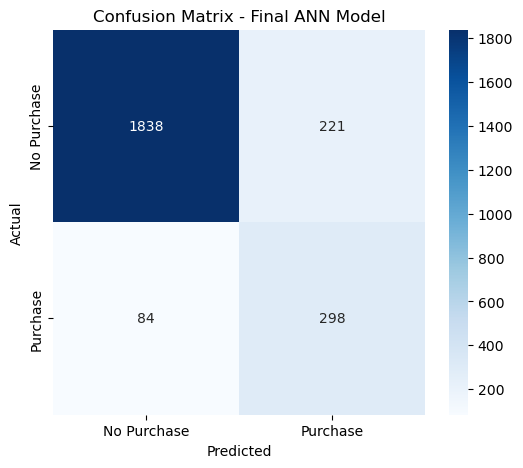

In [69]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Purchase', 'Purchase'],
    yticklabels=['No Purchase', 'Purchase']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Final ANN Model')

plt.show()

## Roc Auc Score

In [70]:
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("Test ROC-AUC Score:", test_roc_auc)

Test ROC-AUC Score: 0.9226826930167392


## Roc Auc Curve

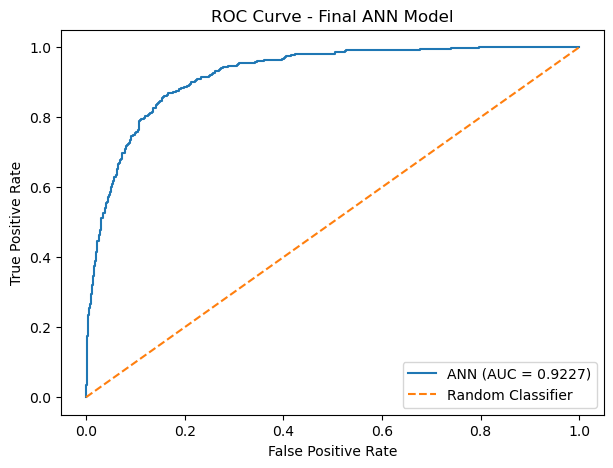

In [72]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_test_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ANN (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Final ANN Model')
plt.legend()

plt.show()

## Final Model Evaluation

The final selected model was an **Artificial Neural Network (ANN) with Early Stopping and without class weights**. A classification threshold of **0.23** was selected using the validation set based on the F1-score of the Purchase class.

The final model was evaluated on the previously untouched test set.

#### Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| No Purchase (0) | 0.95 | 0.89 | 0.92 | 2059 |
| Purchase (1) | 0.57 | 0.77 | 0.65 | 382 |

The model achieved an overall **test accuracy of 87%**.

For the Purchase class, the model achieved a **precision of 0.57**, **recall of 0.77**, and **F1-score of 0.65**. This means that the model successfully identified approximately **77% of the actual purchasers**.

#### Confusion Matrix

```text
[[1832  227]
 [  87  295]]
```

- **True Negatives (TN): 1832** – correctly predicted No Purchase
- **False Positives (FP): 227** – incorrectly predicted Purchase
- **False Negatives (FN): 87** – actual purchasers incorrectly predicted as No Purchase
- **True Positives (TP): 295** – correctly predicted Purchase

The model correctly identified **295 out of 382 actual purchasers**, while 87 purchasers were missed.

#### ROC-AUC Score

The final test ROC-AUC score was:

**ROC-AUC = 0.9222**

This indicates that the model has a strong ability to distinguish between purchasers and non-purchasers.

### Conclusion

The final **ANN with Early Stopping and a classification threshold of 0.23** achieved good performance on unseen test data. Threshold tuning improved the model's ability to identify the minority Purchase class while maintaining a reasonable balance between precision and recall.

The final configuration is:

- **Model:** Artificial Neural Network (ANN)
- **Early Stopping:** Yes
- **Class Weights:** No
- **Classification Threshold:** 0.23
- **Test Accuracy:** 87%
- **Purchase Precision:** 0.57
- **Purchase Recall:** 0.77
- **Purchase F1-Score:** 0.65
- **Test ROC-AUC:** 0.9222

Overall, the model demonstrates good generalization and is effective at predicting online shoppers with purchase intention.

## Individual Shopper Prediction

In [73]:
sample = X_test.iloc[[0]]
sample

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
11640,0,0.0,0,0.0,12,482.5,0.02,0.04,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0


In [74]:
sample_processed = preprocessor.transform(sample)

print("Processed Shape:", sample_processed.shape)

Processed Shape: (1, 73)


In [75]:
pred_prob = model_es.predict(sample_processed)[0][0]

print("Purchase Probability:", pred_prob)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Purchase Probability: 0.037219167


In [76]:
final_threshold = 0.23

if pred_prob >= final_threshold:
    prediction = "Purchase"
else:
    prediction = "No Purchase"

print("Predicted Class:", prediction)

Predicted Class: No Purchase


In [77]:
actual = y_test.iloc[0]

print("Purchase Probability:", pred_prob)
print("Predicted Class:", prediction)
print("Actual Class:", "Purchase" if actual == 1 else "No Purchase")

Purchase Probability: 0.037219167
Predicted Class: No Purchase
Actual Class: No Purchase


# 5. SAVING THE FINAL MODEL, PREPROCESSOR & THRESHOLD

In [78]:
import joblib

In [79]:
# Saving the model
model_es.save('Model/online_shopper_ann.keras')

In [80]:
# Saving the preprocessor
joblib.dump(preprocessor, 'Model/preprocessor.joblib')

['Model/preprocessor.joblib']

In [81]:
# Saving the final threshold
final_threshold = 0.23

joblib.dump(final_threshold, 'Model/threshold.joblib')

['Model/threshold.joblib']

In [1]:
import sys
print(sys.executable)

C:\Users\Lenovo\anaconda3\python.exe


In [2]:
import tensorflow as tf
print(tf.__version__)

2.21.0
